# **Model Pool Analysis**

Coverage, composition, energy, quality and price of the model table. The analysis uses pool v1.2, which differs from v1.3 (used by the pipeline) only in the price snapshot (10 October 2026): the prices of 7 models and the context length of one. Tables are saved as CSV and figures as PDF and PNG in `data/model_pool/analysis_v1.2`.

## Setup

In [ ]:
import json
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

POOL_VERSION = "v1.2"
POOL_DIR = "data/model_pool"

SNAPSHOT_DIR = os.path.join(POOL_DIR, f"snapshots_{POOL_VERSION}")
TABLE_DIR = os.path.join(POOL_DIR, f"analysis_{POOL_VERSION}", "tables")
FIGURE_DIR = os.path.join(POOL_DIR, f"analysis_{POOL_VERSION}", "figures")
os.makedirs(TABLE_DIR, exist_ok=True)
os.makedirs(FIGURE_DIR, exist_ok=True)
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_rows", 300)

pool = pd.read_parquet(os.path.join(POOL_DIR, f"model_pool_{POOL_VERSION}.parquet"))
with open(os.path.join(POOL_DIR, f"model_pool_{POOL_VERSION}_metadata.json")) as f:
    metadata = json.load(f)
snap = {n: pd.read_parquet(os.path.join(SNAPSHOT_DIR, f"{n}.parquet"))
        for n in ["mlenergy", "llmperf", "aienergy", "hub_meta"]}

SOURCES = {"mle": "ML.ENERGY (H100, batch 128)", "llmperf": "LLM-Perf (A100, batch 1)",
           "aies_feb25": "AI Energy Score, Feb 2025 (H100, batch 1)", "aies_dec25": "AI Energy Score, Dec 2025 (H100, batch 1)"}
QUALITY = ["oll_ifeval", "oll_bbh", "oll_math_lvl_5", "oll_gpqa", "oll_musr", "oll_mmlu_pro"]
TIGER_COLS = [c for c in pool.columns if c.startswith("mmlupro_tiger_")
              and c not in ("mmlupro_tiger_name", "mmlupro_tiger_source", "mmlupro_tiger_variant")]
print(f"{len(pool)} models | created {metadata['created_utc']} | prices {metadata['price_snapshot_utc']}")

def save_table(df, name):
    df.to_csv(os.path.join(TABLE_DIR, f"{name}.csv"))
    print(df.to_string())

Mounted at /content/drive
197 models | created 2026-10-10T21:16:00+00:00 | prices 2026-10-10T20:29:36+00:00


In [ ]:
SLOTS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7"]
SOURCE_COLORS = dict(zip(SOURCES, SLOTS))
SPEC_ORDER = ["generalist", "mathematics", "coding", "medicine", "reasoning", "law", "finance"]
SPEC_COLORS = dict(zip(SPEC_ORDER, SLOTS))
TEXT, TEXT2, GRID = "#0b0b0b", "#52514e", "#e5e4df"
plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white", "axes.edgecolor": GRID,
    "axes.labelcolor": TEXT2, "axes.titlecolor": TEXT, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.labelsize": 9, "xtick.color": TEXT2, "ytick.color": TEXT2, "xtick.labelsize": 8, "ytick.labelsize": 8,
    "axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False, "legend.fontsize": 8,
})

def save_figure(fig, name):
    for ext in ("pdf", "png"):
        fig.savefig(os.path.join(FIGURE_DIR, f"{name}.{ext}"), dpi=200, bbox_inches="tight")
    plt.show()

def spec_color(s):
    return SPEC_COLORS.get(s, "#4a3aa7")

def plain_log_axes(ax):
    fmt = plt.matplotlib.ticker.FuncFormatter(lambda v, _: f"{v:g}")
    for axis in (ax.xaxis, ax.yaxis):
        if axis.get_scale() == "log":
            axis.set_major_formatter(fmt)
            axis.set_minor_formatter(plt.matplotlib.ticker.NullFormatter())

## Coverage

`direct` means the model itself was measured by that source; `inherited` means a measured model with the same architecture fingerprint lent its value.

In [3]:
coverage = pd.Series({
    "members": len(pool),
    "config.json read": int(pool["config_ok"].sum()),
    "energy (any source)": int(pool["has_energy"].sum()),
    "energy measured directly": int(pool["energy_direct"].sum()),
    "quality (any benchmark)": int(pool["has_quality"].sum()),
    "price": int(pool["has_price"].sum()),
    "energy + quality": int(pool["complete"].sum()),
    "energy measured directly + quality": int((pool["complete"] & pool["energy_direct"]).sum()),
    "MMLU-Pro (TIGER-Lab), overall": int(pool["mmlupro_tiger_overall"].notna().sum()),
    "MMLU-Pro (TIGER-Lab), per subject": int(pool["mmlupro_tiger_health"].notna().sum()),
    "energy + quality + price": int((pool["complete"] & pool["has_price"]).sum()),
}, name="models")
save_table(coverage.to_frame(), "coverage")

                                    models
members                                197
config.json read                       197
energy (any source)                     98
energy measured directly                31
quality (any benchmark)                157
price                                   39
energy + quality                        77
energy measured directly + quality      17
MMLU-Pro (TIGER-Lab), overall           57
MMLU-Pro (TIGER-Lab), per subject       46
energy + quality + price                16


In [4]:
links = pd.DataFrame({SOURCES[s]: pool[f"{s}_link"].fillna("none").value_counts() for s in SOURCES}).fillna(0).astype(int)
save_table(links, "energy_link_by_source")

           ML.ENERGY (H100, batch 128)  LLM-Perf (A100, batch 1)  AI Energy Score, Feb 2025 (H100, batch 1)  AI Energy Score, Dec 2025 (H100, batch 1)
direct                              22                         0                                          5                                          4
inherited                           12                        12                                         55                                         26
none                               163                       185                                        137                                        167


In [5]:
pool["coverage_class"] = np.select(
    [pool["complete"], pool["has_energy"], pool["has_quality"]],
    ["energy + quality", "energy only", "quality only"], default="neither")
by_spec = pd.crosstab(pool["specialisation"], pool["coverage_class"], margins=True, margins_name="total")
save_table(by_spec, "coverage_by_specialisation")

coverage_class  energy + quality  energy only  neither  quality only  total
specialisation                                                             
coding                         6            2        4             7     19
finance                        0            0        1             0      1
generalist                    59           14       12            68    153
law                            0            1        0             0      1
mathematics                    5            0        0             5     10
medicine                       2            4        2             0      8
reasoning                      5            0        0             0      5
total                         77           21       19            80    197


In [6]:
missing_config = pool.loc[~pool["config_ok"], ["model_key", "specialisation"]]
print(f"{len(missing_config)} models without config.json (gated licence not accepted, or id not on the Hub):")
save_table(missing_config.set_index("model_key"), "models_without_config")

0 models without config.json (gated licence not accepted, or id not on the Hub):
Empty DataFrame
Columns: [specialisation]
Index: []


## Composition

In [7]:
size_band = pd.cut(pool["params_b"], [0, 3, 10, 40, 100, 1e4],
                   labels=["≤3B", "3–10B", "10–40B", "40–100B", ">100B"])
composition = pd.crosstab(size_band.astype(str).replace("nan", "unknown"), pool["specialisation"],
                          margins=True, margins_name="total")
save_table(composition, "models_by_size_and_specialisation")

specialisation  coding  finance  generalist  law  mathematics  medicine  reasoning  total
params_b                                                                                 
10–40B               5        0          36    0            0         1          3     45
3–10B                8        1          59    1            4         4          0     77
40–100B              1        0          17    0            3         2          1     24
>100B                2        0          11    0            0         0          1     14
unknown              0        0           0    0            1         1          0      2
≤3B                  3        0          30    0            2         0          0     35
total               19        1         153    1           10         8          5    197


In [8]:
save_table(pool["org"].value_counts().rename("models").to_frame(), "models_by_provider")

                models
org                   
qwen                48
google              18
mistralai           17
meta-llama          14
nvidia              13
ibm-granite         11
microsoft           10
deepseek-ai          9
01-ai                8
tiiuae               7
huggingfacetb        6
thudm                4
lgai-exaone          4
allenai              4
internlm             4
openai               3
aaditya              2
codellama            2
m42-health           2
tencent              2
swiss-ai             2
upstage              2
bigcode              1
epfl-llm             1
equall               1
biomistral           1
sufe-aiflm-lab       1


### Which quality sources cover the models of each energy source

Energy and quality sources measured models of different periods: low counts mean they describe different generations of models.

In [9]:
QUALITY_SOURCES = {"Open LLM Leaderboard": "oll_mmlu_pro", "MMLU-Pro (TIGER-Lab)": "mmlupro_tiger_overall",
                   "EvalPlus": "evalplus_humaneval_plus", "price (OpenRouter)": "price_out_usd_per_mtok"}
overlap = {}
for src in SOURCES:
    for link in ("direct", "inherited"):
        d = pool[pool[f"{src}_link"] == link]
        overlap[(SOURCES[src], link)] = {"models": len(d), **{q: int(d[c].notna().sum()) for q, c in QUALITY_SOURCES.items()}}
save_table(pd.DataFrame(overlap).T, "energy_source_vs_quality_source")

                                                     models  Open LLM Leaderboard  MMLU-Pro (TIGER-Lab)  EvalPlus  price (OpenRouter)
ML.ENERGY (H100, batch 128)               direct         22                     3                    11         1                  14
                                          inherited      12                     7                     4         3                   2
LLM-Perf (A100, batch 1)                  direct          0                     0                     0         0                   0
                                          inherited      12                    12                     5         0                   0
AI Energy Score, Feb 2025 (H100, batch 1) direct          5                     5                     3         0                   2
                                          inherited      55                    45                    16        13                   4
AI Energy Score, Dec 2025 (H100, batch 1) direct          4   

## Energy

### Agreement between sources on shared architectures

An architecture measured by two sources shows how much the measurement conditions change the result (direct measurements only). AI Energy Score gives joules per query, the others joules per output token.

In [10]:
fp = snap["hub_meta"].set_index("model_key")["arch_fingerprint"]
per_source = {
    "mle_b128": snap["mlenergy"].set_index("model_id")["mle_j_per_out_token"],
    "mle_b8": snap["mlenergy"].set_index("model_id")["mle_b8_j_per_out_token"],
    "llmperf": snap["llmperf"].set_index("model")["llmperf_j_per_out_token"],
    **{f"{c}_per_query": snap["aienergy"].query("aies_campaign == @c.split('_')[1]").set_index("model_key")["aies_j_per_query"]
       for c in ("aies_feb25", "aies_dec25")},
}
frames = []
for name, s in per_source.items():
    d = s.dropna().to_frame("j_per_out_token").assign(source=name)
    d["arch_fingerprint"] = d.index.map(fp)
    frames.append(d.dropna(subset=["arch_fingerprint"]))
measured = pd.concat(frames).reset_index(names="measured_model")
bridges = measured.pivot_table(index="arch_fingerprint", columns="source", values="j_per_out_token", aggfunc="min")
bridges = bridges[bridges.notna().sum(axis=1) >= 2]
names = measured.groupby("arch_fingerprint")["measured_model"].apply(lambda s: ", ".join(sorted(set(s))))
bridges.insert(0, "models", names.reindex(bridges.index))
for a, b in [("llmperf", "mle_b8"), ("llmperf", "mle_b128"), ("mle_b8", "mle_b128"),
             ("aies_feb25_per_query", "mle_b8"), ("aies_dec25_per_query", "mle_b8"),
             ("aies_feb25_per_query", "llmperf"), ("aies_feb25_per_query", "aies_dec25_per_query")]:
    if a in bridges and b in bridges:
        bridges[f"ratio_{a}/{b}"] = bridges[a] / bridges[b]
print(f"{len(bridges)} architectures measured by at least two sources")
save_table(bridges.reset_index(drop=True), "energy_bridges")

23 architectures measured by at least two sources
source                                                                                                                                                                        models  aies_dec25_per_query  aies_feb25_per_query    llmperf  mle_b128     mle_b8  ratio_llmperf/mle_b8  ratio_llmperf/mle_b128  ratio_mle_b8/mle_b128  ratio_aies_feb25_per_query/mle_b8  ratio_aies_dec25_per_query/mle_b8  ratio_aies_feb25_per_query/llmperf  ratio_aies_feb25_per_query/aies_dec25_per_query
0                                                                                                                                             meta-llama/llama-3.1-405b-instruct-fp8                   NaN                   NaN        NaN  2.429513  13.974869                   NaN                     NaN               5.752129                                NaN                                NaN                                 NaN                                      

### Energy per output token against model size

Fitted per source as `log(energy) = a + b·log(active parameters)`.

In [ ]:
# every model measured by a source (members or not), with its parameter count from the Hub
# (active parameters from ML.ENERGY for mixture-of-experts models)
hub_params = snap["hub_meta"].set_index("model_key")["params_b_hub"]
mle_s = snap["mlenergy"].set_index("model_id")
series = {
    "mle": pd.DataFrame({"params_active_b": mle_s["mle_activated_params_billions"],
                         "j": mle_s["mle_j_per_out_token"]}),
    "llmperf": pd.DataFrame({"params_active_b": hub_params.reindex(snap["llmperf"]["model"]).values,
                             "j": snap["llmperf"]["llmperf_j_per_out_token"].values},
                            index=snap["llmperf"]["model"]),
}
fits = {}
for src, d in series.items():
    d = d.dropna()
    d = d[(d["params_active_b"] > 0) & (d["j"] > 0)]
    series[src] = d
    if len(d) >= 3:
        b, a = np.polyfit(np.log10(d["params_active_b"]), np.log10(d["j"]), 1)
        fits[SOURCES[src]] = {"n_models": len(d), "exponent_b": round(b, 3), "energy_x_for_10x_params": round(10 ** b, 2)}
save_table(pd.DataFrame(fits).T, "energy_vs_size_fit")

                             n_models  exponent_b  energy_x_for_10x_params
ML.ENERGY (H100, batch 128)      21.0       0.559                     3.62
LLM-Perf (A100, batch 1)         21.0       0.525                     3.35


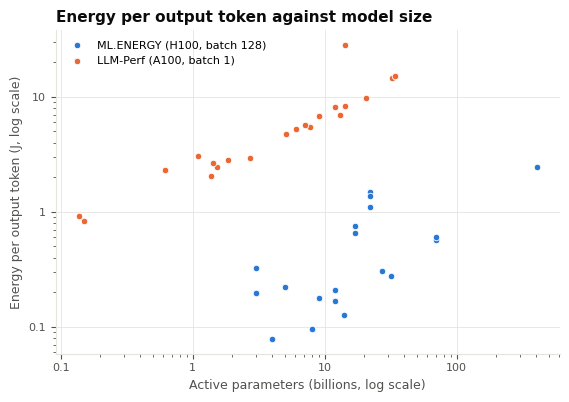

In [12]:
fig, ax = plt.subplots(figsize=(6.5, 4.2))
for src, d in series.items():
    ax.scatter(d["params_active_b"], d["j"], s=22, color=SOURCE_COLORS[src], label=SOURCES[src],
               edgecolor="white", linewidth=0.6, zorder=3)
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("Active parameters (billions, log scale)")
ax.set_ylabel("Energy per output token (J, log scale)")
ax.set_title("Energy per output token against model size", loc="left")
ax.grid(True, which="major", color=GRID, linewidth=0.6); ax.set_axisbelow(True)
ax.legend(loc="best")
plain_log_axes(ax)
save_figure(fig, "fig_energy_vs_size")

### Input tokens against output tokens (LLM-Perf)

At batch 1 the decode is inefficient, so this ratio is an upper bound for batched serving.

In [13]:
lp = snap["llmperf"].copy()
lp["out_over_in"] = lp["llmperf_j_per_out_token"] / lp["llmperf_j_per_in_token"]
ratio_stats = lp["out_over_in"].describe(percentiles=[0.1, 0.5, 0.9]).round(1)
save_table(ratio_stats.to_frame("output J / input J"), "llmperf_output_vs_input_energy")

       output J / input J
count                35.0
mean                148.5
std                  30.8
min                  63.6
10%                 115.2
50%                 149.2
90%                 194.0
max                 201.0


## Quality

In [14]:
tiger_pct = pool[TIGER_COLS] * 100          # TIGER-Lab publishes 0-1; shown as percentages like the others
quality_stats = pd.concat([pool[QUALITY + [c for c in pool.columns if c.startswith("evalplus_")]], tiger_pct],
                          axis=1).describe().T.round(1)
quality_stats["models"] = quality_stats["count"].astype(int)
save_table(quality_stats, "quality_by_benchmark")

                                count  mean   std   min   25%   50%   75%   max  models
oll_ifeval                      135.0  52.7  20.4   0.0  39.8  55.0  69.2  90.0     135
oll_bbh                         135.0  27.7  16.5   2.1  14.3  25.7  43.1  62.8     135
oll_math_lvl_5                  135.0  19.9  18.1   0.0   3.9  16.1  27.9  71.5     135
oll_gpqa                        135.0   6.4   4.9   0.0   2.5   5.4   9.5  24.9     135
oll_musr                        135.0   8.8   5.3   0.8   4.3   8.2  12.9  23.9     135
oll_mmlu_pro                    135.0  24.7  13.9   1.0  12.7  25.1  35.8  51.9     135
evalplus_humaneval               23.0  61.6  20.6  17.7  44.2  67.7  75.9  92.1      23
evalplus_humaneval_plus          23.0  56.2  20.5  15.2  38.4  60.4  71.6  87.2      23
evalplus_mbpp                    21.0  67.3  15.7  29.8  59.5  70.4  78.0  90.5      21
evalplus_mbpp_plus               21.0  56.3  14.2  23.3  49.7  56.9  65.6  77.0      21
mmlupro_tiger_overall           

### Specialists against generalists in their own domain

Generalists between half and double the parameters of the specialist; domain benchmark MATH Lvl 5 (mathematics) or HumanEval+ (coding), MMLU-Pro as general benchmark.

In [15]:
DOMAIN_BENCH = {"mathematics": "oll_math_lvl_5", "coding": "evalplus_humaneval_plus"}
gen = pool[pool["specialisation"] == "generalist"]
rows = []
for _, s in pool[pool["specialisation"].isin(DOMAIN_BENCH)].iterrows():
    bench = DOMAIN_BENCH[s["specialisation"]]
    if pd.isna(s.get(bench)) or pd.isna(s["params_b"]):
        continue
    peers = gen[gen["params_b"].between(s["params_b"] / 2, s["params_b"] * 2)].dropna(subset=[bench])
    rows.append({
        "specialist": s["model_key"], "domain": s["specialisation"], "params_b": round(s["params_b"], 1),
        "domain_benchmark": bench, "specialist_score": round(s[bench], 1),
        "best_peer": peers.loc[peers[bench].idxmax(), "model_key"] if len(peers) else None,
        "best_peer_score": round(peers[bench].max(), 1) if len(peers) else np.nan,
        "specialist_mmlu_pro": round(s.get("oll_mmlu_pro", np.nan), 1),
        "best_peer_mmlu_pro": round(peers["oll_mmlu_pro"].max(), 1) if len(peers) else np.nan,
    })
spec_vs_gen = pd.DataFrame(rows)
if len(spec_vs_gen):
    spec_vs_gen["specialist_wins_domain"] = spec_vs_gen["specialist_score"] > spec_vs_gen["best_peer_score"]
save_table(spec_vs_gen, "specialists_vs_generalists")

                                     specialist       domain  params_b         domain_benchmark  specialist_score                              best_peer  best_peer_score  specialist_mmlu_pro  best_peer_mmlu_pro  specialist_wins_domain
0          bigcode/starcoder2-15b-instruct-v0.1       coding      16.0  evalplus_humaneval_plus              60.4       meta-llama/llama-3.1-8b-instruct             62.8                  NaN                31.1                   False
1           codellama/codellama-70b-instruct-hf       coding      69.0  evalplus_humaneval_plus              65.9   meta-llama/meta-llama-3-70b-instruct             72.0                  NaN                46.7                   False
2      deepseek-ai/deepseek-coder-1.3b-instruct       coding       1.3  evalplus_humaneval_plus              60.4                 google/gemma-1.1-2b-it             17.7                  NaN                 5.4                    True
3       deepseek-ai/deepseek-coder-33b-instruct       coding

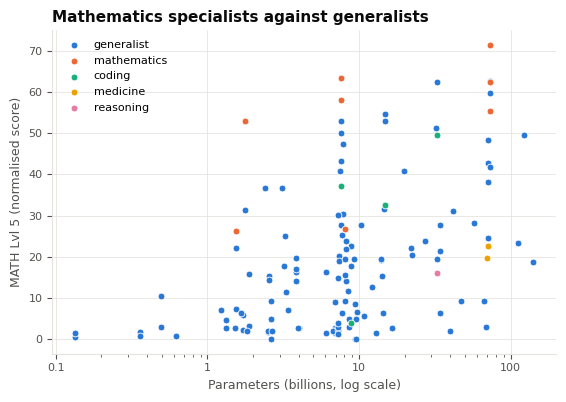

In [16]:
fig, ax = plt.subplots(figsize=(6.5, 4.2))
d = pool.dropna(subset=["params_b", "oll_math_lvl_5"])
for spec in [s for s in SPEC_ORDER if s in set(d["specialisation"])]:
    e = d[d["specialisation"] == spec]
    ax.scatter(e["params_b"], e["oll_math_lvl_5"], s=24, color=spec_color(spec), label=spec,
               edgecolor="white", linewidth=0.6, zorder=3)
ax.set_xscale("log")
ax.set_xlabel("Parameters (billions, log scale)")
ax.set_ylabel("MATH Lvl 5 (normalised score)")
ax.set_title("Mathematics specialists against generalists", loc="left")
ax.grid(True, color=GRID, linewidth=0.6); ax.set_axisbelow(True)
ax.legend(loc="best")
plain_log_axes(ax)
save_figure(fig, "fig_math_vs_size")

### MMLU-Pro per subject (TIGER-Lab)

Only rows run by TIGER-Lab have subjects.

In [17]:
subj_cols = [c for c in TIGER_COLS if c != "mmlupro_tiger_overall"]
subjects = pool.set_index("model_key")[["specialisation", "mmlupro_tiger_source", "mmlupro_tiger_overall"] + subj_cols]
subjects = subjects.dropna(subset=subj_cols, how="all")
subjects[["mmlupro_tiger_overall"] + subj_cols] = (subjects[["mmlupro_tiger_overall"] + subj_cols] * 100).round(1)
subjects.columns = [c.removeprefix("mmlupro_tiger_") for c in subjects.columns]
print(f"{len(subjects)} models with per-subject scores")
save_table(subjects.sort_values(["specialisation", "overall"], ascending=[True, False]), "mmlu_pro_by_subject")

46 models with per-subject scores
                                          specialisation     source  overall  biology  business  chemistry  computer_science  economics  engineering  health  history   law  math  philosophy  physics  psychology  other
model_key                                                                                                                                                                                                                
deepseek-ai/deepseek-coder-v2-instruct            coding  TIGER-Lab     63.6     76.6      73.3       66.9              68.8       74.6         51.7    61.1     51.8  35.1  63.4        56.2     68.1        72.1   65.4
mistralai/mistral-large-instruct-2411         generalist  TIGER-Lab     67.9     83.7      71.9       62.9              76.8       76.4         51.2    74.6     66.4  50.4  70.9        65.3     66.0        78.4   70.7
meta-llama/llama-3.3-70b-instruct             generalist  TIGER-Lab     65.9     81.9      68.

### Specialists against generalists, per MMLU-Pro subject

Same comparison on the MMLU-Pro subject that matches the specialization; only models run by TIGER-Lab.

In [18]:
SUBJECT_OF = {"medicine": "mmlupro_tiger_health", "law": "mmlupro_tiger_law", "mathematics": "mmlupro_tiger_math",
              "coding": "mmlupro_tiger_computer_science", "finance": "mmlupro_tiger_business"}
rows = []
for _, s in pool[pool["specialisation"].isin(SUBJECT_OF)].iterrows():
    col = SUBJECT_OF[s["specialisation"]]
    if pd.isna(s.get(col)) or pd.isna(s["params_b"]):
        continue
    peers = gen[gen["params_b"].between(s["params_b"] / 2, s["params_b"] * 2)].dropna(subset=[col])
    rows.append({
        "specialist": s["model_key"], "domain": s["specialisation"], "params_b": round(s["params_b"], 1),
        "subject": col.removeprefix("mmlupro_tiger_"), "specialist_score": round(100 * s[col], 1),
        "best_peer": peers.loc[peers[col].idxmax(), "model_key"] if len(peers) else None,
        "best_peer_score": round(100 * peers[col].max(), 1) if len(peers) else np.nan,
        "specialist_overall": round(100 * s["mmlupro_tiger_overall"], 1),
        "best_peer_overall": round(100 * peers.loc[peers[col].idxmax(), "mmlupro_tiger_overall"], 1) if len(peers) else np.nan,
    })
spec_vs_gen_subject = pd.DataFrame(rows)
if len(spec_vs_gen_subject):
    spec_vs_gen_subject["specialist_wins_subject"] = spec_vs_gen_subject["specialist_score"] > spec_vs_gen_subject["best_peer_score"]
print(f"{len(spec_vs_gen_subject)} specialists with a score on their subject")
save_table(spec_vs_gen_subject, "specialists_vs_generalists_by_subject")

2 specialists with a score on their subject
                               specialist       domain  params_b           subject  specialist_score                              best_peer  best_peer_score  specialist_overall  best_peer_overall  specialist_wins_subject
0  deepseek-ai/deepseek-coder-v2-instruct       coding     235.7  computer_science              68.8  mistralai/mistral-large-instruct-2411             76.8                63.6               67.9                    False
1             mistralai/mathstral-7b-v0.1  mathematics       7.2              math              47.7                 qwen/qwen2-7b-instruct             58.0                42.0               47.2                    False


### Specialist and generalist with the same architecture

Same architecture fingerprint, hence the same energy by construction: only quality differs.

In [19]:
ENERGY_COLS = {"mle": "mle_j_per_out_token", "llmperf": "llmperf_j_per_out_token",
               "aies_feb25": "aies_feb25_j_per_query", "aies_dec25": "aies_dec25_j_per_query"}
BENCH_COLS = ["oll_math_lvl_5", "oll_mmlu_pro", "oll_ifeval", "oll_bbh", "evalplus_humaneval_plus",
              "mmlupro_tiger_overall", "mmlupro_tiger_math", "mmlupro_tiger_health", "mmlupro_tiger_law"]
rows = []
specs = pool[(pool["specialisation"] != "generalist") & pool["arch_fingerprint"].notna()]
for _, s in specs.iterrows():
    twins = gen[gen["arch_fingerprint"] == s["arch_fingerprint"]]
    for _, g in twins.iterrows():
        r = {"specialist": s["model_key"], "domain": s["specialisation"], "generalist": g["model_key"],
             "params_b": round(s["params_b"], 1) if pd.notna(s["params_b"]) else np.nan}
        for src, col in ENERGY_COLS.items():
            if pd.notna(s.get(col)) or pd.notna(g.get(col)):
                r[f"energy_{src}_specialist"], r[f"energy_{src}_generalist"] = s.get(col), g.get(col)
        for b in BENCH_COLS:
            if pd.notna(s.get(b)) and pd.notna(g.get(b)):
                scale = 100 if b.startswith("mmlupro_tiger_") else 1
                r[f"{b}_specialist"], r[f"{b}_generalist"] = round(scale * s[b], 1), round(scale * g[b], 1)
        rows.append(r)
same_arch = pd.DataFrame(rows)
if len(same_arch):
    n_bench = same_arch.filter(like="_specialist").drop(columns=[c for c in same_arch if c.startswith("energy_")], errors="ignore").notna().sum(axis=1)
    same_arch = same_arch[n_bench > 0]          # keep pairs with at least one shared benchmark
print(f"{len(same_arch)} specialist–generalist pairs with the same architecture and a shared benchmark")
save_table(same_arch.set_index(["specialist", "generalist"]), "same_architecture_pairs")

51 specialist–generalist pairs with the same architecture and a shared benchmark
                                                                                    domain  params_b  energy_aies_feb25_specialist  energy_aies_feb25_generalist  oll_math_lvl_5_specialist  oll_math_lvl_5_generalist  oll_mmlu_pro_specialist  oll_mmlu_pro_generalist  oll_ifeval_specialist  oll_ifeval_generalist  oll_bbh_specialist  oll_bbh_generalist  energy_mle_specialist  energy_mle_generalist  energy_aies_dec25_specialist  energy_aies_dec25_generalist  evalplus_humaneval_plus_specialist  evalplus_humaneval_plus_generalist  mmlupro_tiger_overall_specialist  mmlupro_tiger_overall_generalist  mmlupro_tiger_math_specialist  mmlupro_tiger_math_generalist  mmlupro_tiger_health_specialist  mmlupro_tiger_health_generalist  mmlupro_tiger_law_specialist  mmlupro_tiger_law_generalist
specialist                          generalist                                                                                        

## Energy against price

Spearman correlation on models with a directly measured energy and a price.

In [20]:
corr_rows = []
for src, col in [("mle", "mle_j_per_out_token"), ("llmperf", "llmperf_j_per_out_token")]:
    d = pool[(pool[f"{src}_link"].notna()) & pool["has_price"]][["model_key", col, "price_out_usd_per_mtok"]].dropna()
    if len(d) >= 3:
        corr_rows.append({"energy_source": SOURCES[src], "models": len(d),
                          "spearman": round(d[col].corr(d["price_out_usd_per_mtok"], method="spearman"), 2),
                          "pearson_log": round(np.log(d[col]).corr(np.log(d["price_out_usd_per_mtok"])), 2)})
save_table(pd.DataFrame(corr_rows), "energy_vs_price_correlation")

                 energy_source  models  spearman  pearson_log
0  ML.ENERGY (H100, batch 128)      15      0.77         0.77


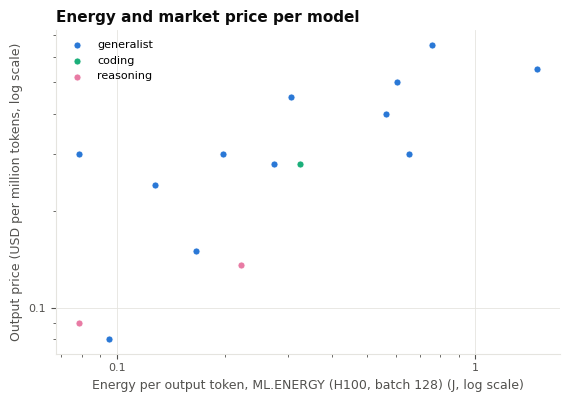

In [21]:
d = pool[pool["has_price"] & pool["mle_j_per_out_token"].notna()]
src, col = "mle", "mle_j_per_out_token"
if len(d) < 3:
    d = pool[pool["has_price"] & pool["llmperf_j_per_out_token"].notna()]
    src, col = "llmperf", "llmperf_j_per_out_token"
fig, ax = plt.subplots(figsize=(6.5, 4.2))
for spec in [s for s in SPEC_ORDER if s in set(d["specialisation"])]:
    e = d[d["specialisation"] == spec]
    ax.scatter(e[col], e["price_out_usd_per_mtok"], s=26, color=spec_color(spec), label=spec,
               edgecolor="white", linewidth=0.6, zorder=3)
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel(f"Energy per output token, {SOURCES[src]} (J, log scale)")
ax.set_ylabel("Output price (USD per million tokens, log scale)")
ax.set_title("Energy and market price per model", loc="left")
ax.grid(True, color=GRID, linewidth=0.6); ax.set_axisbelow(True)
if len(d):
    ax.legend(loc="best")
plain_log_axes(ax)
save_figure(fig, "fig_energy_vs_price")

## Quality against energy: the Pareto front

Quality: mean of the six Open LLM Leaderboard benchmarks; energy from one source at a time.

In [22]:
def pareto(df, q, e):
    df = df.sort_values([e, q], ascending=[True, False])
    best, keep = -np.inf, []
    for _, r in df.iterrows():
        keep.append(r[q] > best)
        best = max(best, r[q])
    return df.assign(on_front=keep)

pool["oll_mean6"] = pool[QUALITY].mean(axis=1, skipna=False)
fronts = {}
for src, col in [("llmperf", "llmperf_j_per_out_token"), ("mle", "mle_j_per_out_token")]:
    d = pool.dropna(subset=["oll_mean6", col])
    if len(d):
        fronts[src] = pareto(d, "oll_mean6", col)[["model_key", "specialisation", "params_b", col, "oll_mean6", "on_front"]]
        save_table(fronts[src].set_index("model_key"), f"pareto_{src}")
{k: int(v["on_front"].sum()) for k, v in fronts.items()}

                              specialisation   params_b  llmperf_j_per_out_token  oll_mean6  on_front
model_key                                                                                            
qwen/qwen1.5-0.5b-chat            generalist   0.619570                 2.326473   5.678162      True
qwen/qwen1.5-1.8b-chat            generalist   1.836829                 2.804396   9.257783      True
01-ai/yi-1.5-6b-chat              generalist   6.061036                 5.203436  22.784006      True
01-ai/yi-6b-chat                  generalist   6.061036                 5.203436  14.117650     False
qwen/qwen1.5-7b-chat              generalist   7.721325                 5.463619  17.620987     False
qwen/qwen1.5-14b-chat             generalist  14.167291                 8.335385  23.566106      True
internlm/internlm2_5-20b-chat     generalist  19.861150                10.302418  38.879596      True
qwen/qwen1.5-32b-chat             generalist  32.512218                14.697041  

{'llmperf': 5, 'mle': 3}

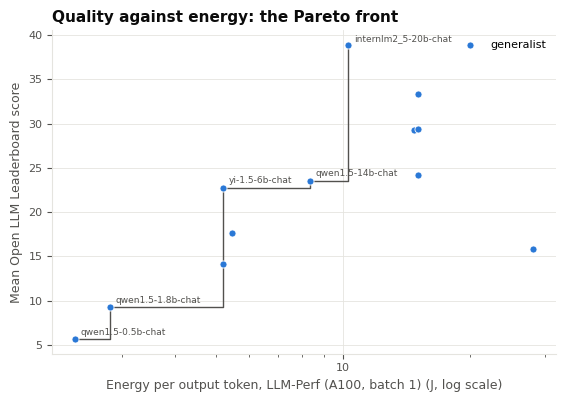

In [23]:
if fronts:
    src = max(fronts, key=lambda k: len(fronts[k]))
    d, col = fronts[src], [c for c in fronts[src].columns if c.endswith("_per_out_token")][0]
    fig, ax = plt.subplots(figsize=(6.5, 4.2))
    for spec in [s for s in SPEC_ORDER if s in set(d["specialisation"])]:
        e = d[d["specialisation"] == spec]
        ax.scatter(e[col], e["oll_mean6"], s=26, color=spec_color(spec), label=spec,
                   edgecolor="white", linewidth=0.6, zorder=3)
    f = d[d["on_front"]].sort_values(col)
    ax.step(f[col], f["oll_mean6"], where="post", color=TEXT2, linewidth=1, zorder=2)
    for _, r in f.iterrows():
        ax.annotate(r["model_key"].split("/")[-1], (r[col], r["oll_mean6"]), fontsize=6.5,
                    color=TEXT2, xytext=(4, 3), textcoords="offset points")
    ax.set_xscale("log")
    ax.set_xlabel(f"Energy per output token, {SOURCES[src]} (J, log scale)")
    ax.set_ylabel("Mean Open LLM Leaderboard score")
    ax.set_title("Quality against energy: the Pareto front", loc="left")
    ax.grid(True, color=GRID, linewidth=0.6); ax.set_axisbelow(True)
    ax.legend(loc="best")
    plain_log_axes(ax)
    save_figure(fig, "fig_pareto")

## Shortlist of complete models

In [24]:
def energy_sources(r):
    # e.g. "mle:direct, aies:inherited(meta-llama/llama-3.1-8b-instruct)"
    out = []
    for src in SOURCES:
        link = r.get(f"{src}_link")
        if isinstance(link, str):
            out.append(f"{src}:{link}" + (f"({r[f'{src}_donor']})" if link == "inherited" else ""))
    return ", ".join(out)
pool["energy_sources"] = pool.apply(energy_sources, axis=1)
short_cols = ["model_key", "specialisation", "params_b", "params_active_b", "context_window", "energy_sources",
              "mle_j_per_out_token", "mle_b8_j_per_out_token", "llmperf_j_per_in_token", "llmperf_j_per_out_token",
              "aies_feb25_j_per_query", "aies_dec25_j_per_query",
              "oll_math_lvl_5", "oll_mmlu_pro", "oll_ifeval", "evalplus_humaneval_plus",
              "mmlupro_tiger_overall", "mmlupro_tiger_source",
              "price_in_usd_per_mtok", "price_out_usd_per_mtok"]
shortlist = (pool[pool["complete"]][[c for c in short_cols if c in pool]]
                 .sort_values(["specialisation", "params_b"]).round(4))
print(f"{len(shortlist)} complete models")
save_table(shortlist.set_index("model_key"), "shortlist_complete_models")

77 complete models
                                              specialisation  params_b  params_active_b  context_window                                                                                                                                                      energy_sources  mle_j_per_out_token  mle_b8_j_per_out_token  llmperf_j_per_in_token  llmperf_j_per_out_token  aies_feb25_j_per_query  aies_dec25_j_per_query  oll_math_lvl_5  oll_mmlu_pro  oll_ifeval  evalplus_humaneval_plus  mmlupro_tiger_overall mmlupro_tiger_source  price_in_usd_per_mtok  price_out_usd_per_mtok
model_key                                                                                                                                                                                                                                                                                                                                                                                                                    

## Core pool

Energy from ML.ENERGY only, quality from the Open LLM Leaderboard only.

In [25]:
core = pd.read_parquet(os.path.join(POOL_DIR, f"model_pool_core_{POOL_VERSION}.parquet"))
summary_cols = ["model_key", "core_role", "params_b", "weights_gb", "gpus_needed_est", "mle_num_gpus", "context_window",
                "mle_link", "mle_donor", "mle_j_per_out_token", "mle_b8_j_per_out_token", "mle_avg_output_len",
                "oll_math_lvl_5", "oll_mmlu_pro", "oll_gpqa", "oll_ifeval", "oll_bbh", "oll_musr",
                "price_out_usd_per_mtok"]
save_table(core[[c for c in summary_cols if c in core]].set_index("model_key").round(3), "core_pool")

                                             core_role  params_b  weights_gb  gpus_needed_est  mle_num_gpus  context_window   mle_link                          mle_donor  mle_j_per_out_token  mle_b8_j_per_out_token  mle_avg_output_len  oll_math_lvl_5  oll_mmlu_pro  oll_gpqa  oll_ifeval  oll_bbh  oll_musr  price_out_usd_per_mtok
model_key                                                                                                                                                                                                                                                                                                                                
aaditya/llama3-openbiollm-70b                 medicine    70.000         NaN              NaN           4.0          8192.0  inherited  meta-llama/llama-3.1-70b-instruct                0.563                   3.759             358.930          19.713        42.967     9.732      75.967   47.147    14.348                     NaN
m42-health

### Quality per domain in the core (MMLU-Pro per subject, Open LLM protocol)

In [26]:
subj = [c for c in core.columns if c.startswith("mmlupro_oll_")]
if subj:
    prof = (core.set_index("model_key")[subj] * 100).round(1)
    prof.columns = [c.removeprefix("mmlupro_oll_") for c in subj]
    prof.insert(0, "core_role", core.set_index("model_key")["core_role"])
    save_table(prof, "core_mmlu_pro_by_subject")
else:
    print("No per-subject scores loaded: accept the details pages listed by the builder and run it again.")

                                             core_role  biology  business  chemistry  computer_science  economics  engineering  health  history   law  math  other  philosophy  physics  psychology
model_key                                                                                                                                                                                          
aaditya/llama3-openbiollm-70b                 medicine     77.8      38.9       34.5              50.7       64.6         37.9    67.4     61.7  39.8  35.8   52.6        50.1     36.6        70.4
m42-health/llama3-med42-70b                   medicine     78.0      40.6       33.7              55.9       64.5         40.1    66.3     59.3  39.4  37.9   55.7        50.7     38.6        70.8
meta-llama/llama-3.1-70b-instruct           generalist     80.5      40.9       36.2              59.0       69.7         39.6    67.4     64.0  49.3  40.9   59.0        57.5     41.8        75.1
meta-llama/llama-3.1

### Specialists against the generalists of the same size, inside the core

Generalists with the same architecture (same energy per token), with the domain benchmark and MMLU-Pro.

In [27]:
DOMAIN_COL = {"mathematics": ["oll_math_lvl_5", "mmlupro_oll_math"], "medicine": ["mmlupro_oll_health"]}
rows = []
gen_core = core[core["core_role"] == "generalist"]
for _, s in core[core["core_role"] != "generalist"].iterrows():
    for _, g in gen_core[gen_core["arch_fingerprint"] == s["arch_fingerprint"]].iterrows():
        r = {"specialist": s["model_key"], "generalist": g["model_key"], "domain": s["core_role"],
             "energy_j_per_token": s["mle_j_per_out_token"]}
        for c in DOMAIN_COL[s["core_role"]] + ["oll_mmlu_pro"]:
            if c in core:
                scale = 100 if c.startswith("mmlupro_oll_") else 1
                r[f"{c}_specialist"], r[f"{c}_generalist"] = round(scale * s[c], 1), round(scale * g[c], 1)
        rows.append(r)
save_table(pd.DataFrame(rows), "core_specialists_vs_generalists")

                      specialist                                 generalist       domain  energy_j_per_token  mmlupro_oll_health_specialist  mmlupro_oll_health_generalist  oll_mmlu_pro_specialist  oll_mmlu_pro_generalist  oll_math_lvl_5_specialist  oll_math_lvl_5_generalist  mmlupro_oll_math_specialist  mmlupro_oll_math_generalist
0  aaditya/llama3-openbiollm-70b          meta-llama/llama-3.1-70b-instruct     medicine            0.563366                           67.4                           67.4                     43.0                     47.9                        NaN                        NaN                          NaN                          NaN
1  aaditya/llama3-openbiollm-70b          meta-llama/llama-3.3-70b-instruct     medicine            0.563366                           67.4                           67.6                     43.0                     48.1                        NaN                        NaN                          NaN                          NaN
2

### Parameters for the pipeline that come from the wider data

ML.ENERGY gives no prefill/decode split; the LLM-Perf ratio (A100, batch 1) is reported as a candidate parameter, not applied.

In [28]:
lp = snap["llmperf"]
ratio = (lp["llmperf_j_per_out_token"] / lp["llmperf_j_per_in_token"]).describe(percentiles=[0.1, 0.5, 0.9]).round(1)
save_table(ratio.to_frame("output J / input J (LLM-Perf)"), "input_output_energy_ratio")

       output J / input J (LLM-Perf)
count                           35.0
mean                           148.5
std                             30.8
min                             63.6
10%                            115.2
50%                            149.2
90%                            194.0
max                            201.0


## Saved files

In [29]:
for folder in (TABLE_DIR, FIGURE_DIR):
    print(folder)
    for name in sorted(os.listdir(folder)):
        print("  ", name)

/content/drive/MyDrive/thesis/model_pool/analysis_v1.2/tables
   core_mmlu_pro_by_subject.csv
   core_pool.csv
   core_specialists_vs_generalists.csv
   coverage.csv
   coverage_by_specialisation.csv
   energy_bridges.csv
   energy_link_by_source.csv
   energy_source_vs_quality_source.csv
   energy_vs_price_correlation.csv
   energy_vs_size_fit.csv
   input_output_energy_ratio.csv
   llmperf_output_vs_input_energy.csv
   mmlu_pro_by_subject.csv
   models_by_provider.csv
   models_by_size_and_specialisation.csv
   models_without_config.csv
   pareto_llmperf.csv
   pareto_mle.csv
   quality_by_benchmark.csv
   same_architecture_pairs.csv
   shortlist_complete_models.csv
   specialists_vs_generalists.csv
   specialists_vs_generalists_by_subject.csv
/content/drive/MyDrive/thesis/model_pool/analysis_v1.2/figures
   fig_energy_vs_price.pdf
   fig_energy_vs_price.png
   fig_energy_vs_size.pdf
   fig_energy_vs_size.png
   fig_math_vs_size.pdf
   fig_math_vs_size.png
   fig_pareto.pdf
   fig_pa